# BUSI2066 · Week 9 — Two Categories at Once: Chi-square


### Before you start

Drag in **this notebook** and **`segments.csv`**, and select the kernel.

### Today

Last week both columns were numbers. This week **both are categories** — and most of your survey is
categories. *Which brand do you prefer? Have you bought from them? Which age band are you in?*

> **Is whether a customer subscribes related to which segment they are in?**

Two categories, one table of counts, and one test.

### The rule

> **AI explains. It does not write.**

---
# Part 0 · Set up, and the file

In [36]:
%pip install -q pandas seaborn scipy statsmodels


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('segments.csv')

print(df.shape)
df.head()

(300, 7)


,age,gender,income,kids,ownHome,subscribe,Segment
0,47.316133,Male,49482.810438,2,ownNo,subNo,Suburb mix
1,31.386839,Male,35546.288300,1,ownYes,subNo,Suburb mix
2,43.200342,Male,44169.186377,0,ownYes,subNo,Suburb mix
3,37.316995,Female,81041.986385,1,ownNo,subNo,Suburb mix
4,40.954390,Female,79353.014443,3,ownYes,subNo,Suburb mix


**300 customers, 7 columns**, from a marketing database that groups customers into segments.

| Column | Type | Values |
|---|---|---|
| `age` · `income` · `kids` | numbers | |
| `gender` | nominal | Female · Male |
| `ownHome` | nominal | ownYes · ownNo |
| `subscribe` | nominal | subYes · subNo — **subscribes to the company's service** |
| `Segment` | nominal | Suburb mix · Travelers · Moving up · Urban hip |

⚠️ **Simulated.** Round group sizes (100 · 80 · 70 · 50) and an income column with a **negative
minimum** are the giveaways — real incomes are not negative. Use it for the method, not for the
business conclusion.

In [38]:
df.describe(include='all')

,age,gender,income,kids,ownHome,subscribe,Segment
count,300.000000,300,300.000000,300.000000,300,300,300
unique,NaN,2,NaN,NaN,2,2,4
top,NaN,Female,NaN,NaN,ownNo,subNo,Suburb mix
freq,NaN,157,NaN,NaN,159,260,100
mean,41.199650,NaN,50936.536184,1.270000,NaN,NaN,NaN
std,12.707427,NaN,20137.549430,1.408443,NaN,NaN,NaN
min,19.259932,NaN,-5183.354243,0.000000,NaN,NaN,NaN
25%,33.012059,NaN,39656.283622,0.000000,NaN,NaN,NaN
50%,39.487674,NaN,52014.352449,1.000000,NaN,NaN,NaN
75%,47.895657,NaN,61403.176264,2.000000,NaN,NaN,NaN


`include='all'` makes `describe()` report the text columns too: `unique`, `top` and `freq` rows.
Read the `top` row — the most common value of each category. `subNo` with freq 260 means **only 40
of 300 subscribe**. That number matters all day.

---
# Part 1 · Describe the difference

Three research questions:

| RQ | Question | Type |
|---|---|---|
| **RQ1** | Are the four segments the same size? | Descriptive |
| **RQ2** | Is subscribing related to segment? | Relational |
| **RQ3** | Is subscribing related to gender? | Relational |

## 1.1 One category — counts and proportions

You know this from week 5.

In [39]:
print(df['Segment'].value_counts())
print()
print(df['Segment'].value_counts(normalize=True).round(3))

Segment
Suburb mix    100
Travelers      80
Moving up      70
Urban hip      50
Name: count, dtype: int64

Segment
Suburb mix    0.333
Travelers     0.267
Moving up     0.233
Urban hip     0.167
Name: proportion, dtype: float64


100 · 80 · 70 · 50. Not equal — but is that *sampling variability*, or are the segments really
different sizes? That is RQ1, and it is Part 3.

## 1.2 Two categories — the crosstab

A **two-way frequency table** counts how many customers fall in every combination of two categories.
Pandas calls it a crosstab.

In [40]:
table2 = pd.crosstab(df['Segment'], df['subscribe'])
table2

subscribe,subNo,subYes
Segment,,
Moving up,56,14
Suburb mix,94,6
Travelers,70,10
Urban hip,40,10


Rows are segments, columns are subscribe/not, cells are counts. **This table is the whole of today's
analysis** — everything else is either drawing it or testing it.

Read it: Moving up has 14 subscribers out of 70; Suburb mix has 6 out of 100. The raw counts are
misleading because the groups are different sizes. You want **rates**.

## 1.3 Two-way proportions — the rate per row

In [41]:
pd.crosstab(df['Segment'], df['subscribe'], normalize='index').round(3)

subscribe,subNo,subYes
Segment,,
Moving up,0.800,0.200
Suburb mix,0.940,0.060
Travelers,0.875,0.125
Urban hip,0.800,0.200


`normalize='index'` divides each **row** by its total, so every row sums to 1. Now you can compare:

| Segment | Subscribe rate |
|---|---|
| Moving up | **20.0%** |
| Urban hip | **20.0%** |
| Travelers | 12.5% |
| Suburb mix | **6.0%** |

Moving up and Urban hip subscribe at more than three times the rate of Suburb mix. That is RQ2,
described. Whether it is *real* is Part 3.

⚠️ **`normalize='index'` is rows; `normalize='columns'` is columns; `normalize=True` is the whole
table.** For "the subscribe rate *within each segment*", it is rows. Getting this wrong produces a
table that looks fine and means something else.

## 1.4 Gender — the same two tables

In [42]:
table3 = pd.crosstab(df['gender'], df['subscribe'])
print(table3)
print()
print(pd.crosstab(df['gender'], df['subscribe'], normalize='index').round(3))

subscribe  subNo  subYes
gender                  
Female       136      21
Male         124      19

subscribe  subNo  subYes
gender                  
Female     0.866   0.134
Male       0.867   0.133


**13.4% of women subscribe, 13.3% of men.** Those are as close as two numbers get. Remember this one
— Part 3 tests it.

## 1.5 The marginal sums

The row and column totals of a two-way table are its **marginal sums** — they are written in the
margins. Part 3 needs them.

In [43]:
pd.crosstab(df['gender'], df['subscribe'], margins=True)

subscribe,subNo,subYes,All
gender,,,
Female,136,21,157
Male,124,19,143
All,260,40,300


📖 `margins=True` adds a row and a column called `All`: the marginal sums. Read-level.

157 women and 143 men; 260 non-subscribers and 40 subscribers; 300 in all. Keep these numbers for §3.2.

---
# Part 2 · Draw the difference

## 2.1 One category — one bar per group

First, how many customers are in each segment? `y=` instead of `x=` gives horizontal bars,
which leave room for long labels.

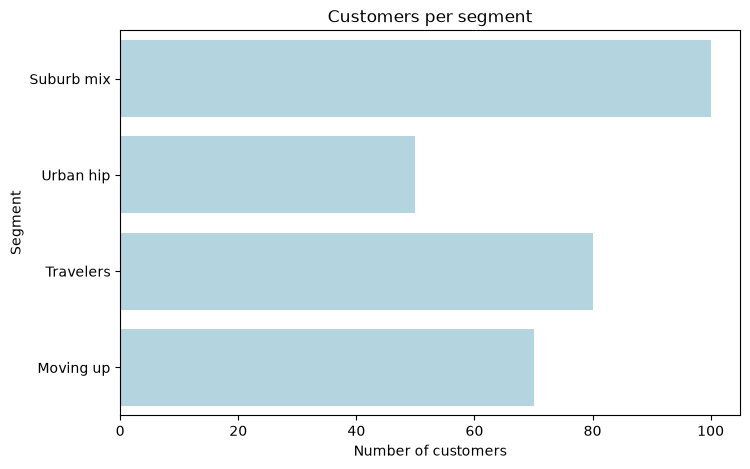

In [44]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, y='Segment', color='lightblue')
plt.xlabel('Number of customers')
plt.title('Customers per segment')
plt.show()

Suburb mix is the biggest, Urban hip the smallest. That is RQ1 drawn. `color=` gives every bar one colour.

## 2.2 Two categories — counts, two ways

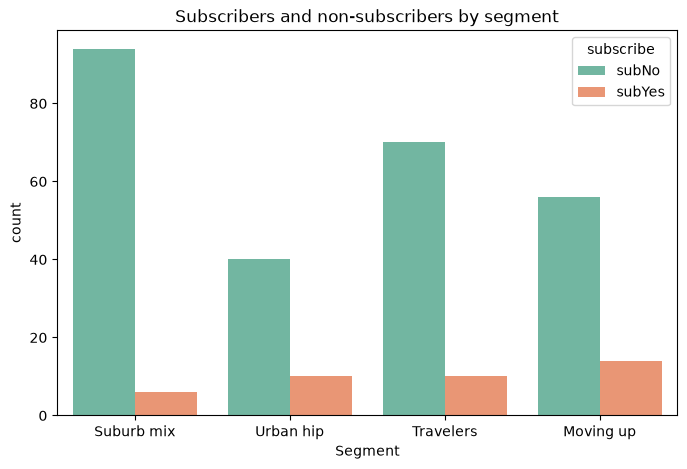

In [45]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Segment', hue='subscribe', palette='Set2')
plt.title('Subscribers and non-subscribers by segment')
plt.show()

`hue='subscribe'` splits every bar in two — the grouped bar chart. It shows **counts**, so Suburb
mix looks like the big segment (it is) and its 6 subscribers are hard to see.

## 2.3 Two categories — rates

For the **rate**, you want each segment's bar to be the same height and split by proportion.

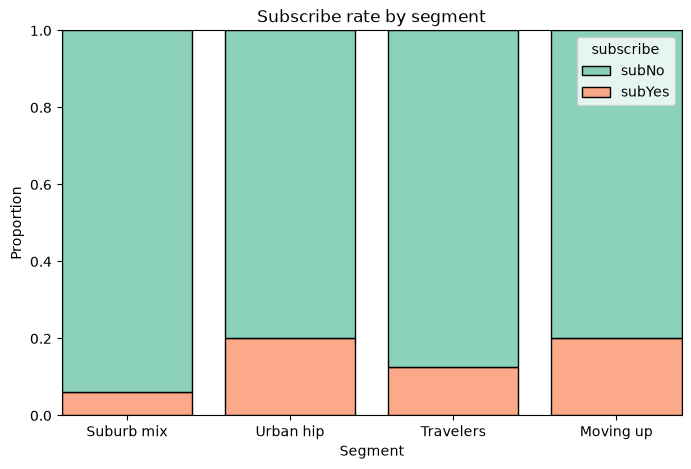

In [46]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Segment', hue='subscribe', multiple='fill', shrink=0.8, palette='Set2')
plt.ylabel('Proportion')
plt.title('Subscribe rate by segment')
plt.show()

📖 `histplot` with `multiple='fill'` is the **filled bar chart** — every bar reaches 1, split by
proportion. `shrink=0.8` puts gaps between the bars. This is read-level: copy it when you want rates.

Now the 20% / 20% / 12.5% / 6% pattern is visible, and Suburb mix's size no longer distorts it.

**Counts when you want to show how many. Filled bars when you want to show the rate.** A report
needs both.

## 2.4 Gender — the same two charts

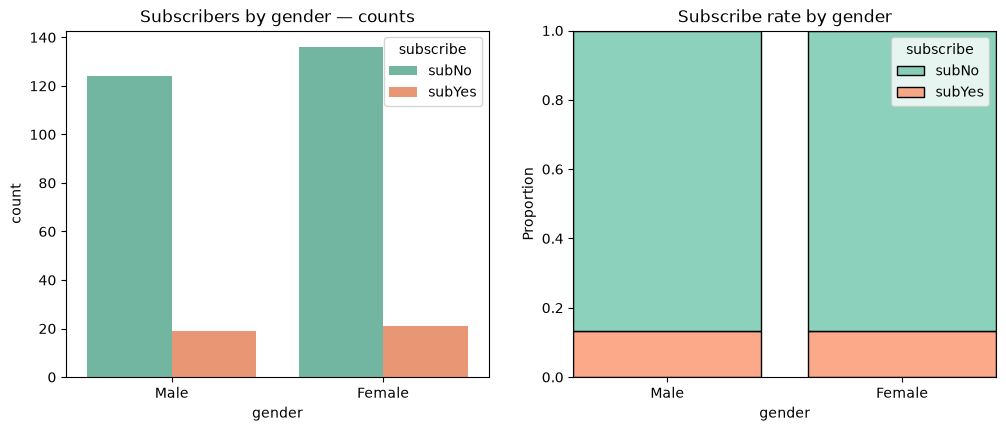

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=df, x='gender', hue='subscribe', palette='Set2', ax=axes[0])
axes[0].set_title('Subscribers by gender — counts')

sns.histplot(data=df, x='gender', hue='subscribe', multiple='fill', shrink=0.8, palette='Set2', ax=axes[1])
axes[1].set_ylabel('Proportion')
axes[1].set_title('Subscribe rate by gender')

plt.show()

Left: more women than men in both bars, because there are more women. Right: the subscribe part is the
same height for both — 13.4% and 13.3%. **The filled chart shows there is almost no difference.**

---
# Part 3 · Is it real? — the chi-square test

A chi-square test compares the counts you **observed** (O) with the counts you would **expect if H₀
were true** (E), and asks whether the gap is bigger than sampling variability would produce.

$$\chi^2 = \sum \frac{(O - E)^2}{E}$$

In words: for **every cell**, take the gap O − E, **square** it (so minus and plus gaps do not cancel),
and **divide by E** (a gap of 5 matters more when only 10 were expected). Then **add up** over all cells.

**Where the p-value comes from.** If H₀ is true, χ² follows a known curve, the **χ² distribution** — its
sampling distribution (week 6). It is never below 0 and is skewed to the right. Its shape depends on
the **degrees of freedom (df)**:

- one category with *k* groups: df = *k* − 1
- two categories with *k* and *n* groups: df = (*k* − 1) × (*n* − 1)

The p-value is the area of that curve to the right of our χ²: *if H₀ were true, how often would a gap
this big or bigger turn up?* Under 5%: reject H₀. The slides show the curve.

## 3.1 One category — are the segments the same size?

| | |
|---|---|
| **H₀** | The four segments have equal numbers of customers |
| **H₁** | They do not |

If H₀ were true, each segment would have 300 ÷ 4 = **75** customers. We observed 100 · 80 · 70 · 50.

In [48]:
from scipy.stats import chisquare

counts = df['Segment'].value_counts()

result = chisquare(f_obs=counts)          # expected = equal shares, by default

print("chi-square:", result.statistic)
print("p:", result.pvalue)

chi-square: 17.333333333333336
p: 0.0006034948344733141


**χ² = 17.3, p = 0.0006.** Reject H₀ — the segments are not the same size in the population.

`f_obs` is the observed counts. Leave `f_exp` out and the test assumes equal expected counts, which
is what H₀ says here. You can supply `f_exp=[...]` for any other expectation.

### The test is sensitive to sample size

Same proportions, a tenth of the data:

In [49]:
result = chisquare(f_obs=counts / 10)      # 10 · 8 · 7 · 5

print("chi-square:", result.statistic)
print("p:", result.pvalue)

chi-square: 1.7333333333333334
p: 0.6295486369494645


Identical proportions — 33%, 27%, 23%, 17% — and **p = 0.63**. Not significant.

The difference between the groups did not change. The **evidence** for it did. Thirty customers
cannot establish what three hundred can. This is week 6's √n, again, and it is why your project
brief sets a minimum sample size.

## 3.2 Two categories — is subscribing related to gender?

| | |
|---|---|
| **H₀** | Subscribing is **not** related to gender — they are independent |
| **H₁** | They are related |

For a two-way table the test is `chi2_contingency`, and you hand it the crosstab.

In [50]:
from scipy.stats import chi2_contingency

result = chi2_contingency(table3)

print("chi-square:", result.statistic)
print("p:", result.pvalue)
print("degrees of freedom:", result.dof)
print()
print("expected counts if H0 were true:")
print(result.expected_freq.round(1))

chi-square: 0.0
p: 1.0
degrees of freedom: 1

expected counts if H0 were true:
[[136.1  20.9]
 [123.9  19.1]]


**χ² = 0.0, p = 1.0.** You will never see a cleaner "no". We fail to reject H₀.

Look at `expected_freq`. Each expected count is **row marginal sum × column marginal sum ÷ total**
(§1.5): if gender and subscribing were unrelated, 157 women × 40 / 300 = **20.9** women would
subscribe. We observed 21. The test does this for every cell, then applies the formula above.

**Why exactly 0?** Every gap here is under 0.1. By the formula, χ² would be 0.0005 — tiny, but not 0.
For a 2 × 2 table, `chi2_contingency` makes a small safety correction by default (**Yates'
correction**): it moves each observed count up to 0.5 closer to its expected count before squaring.
Our gaps are smaller than 0.5, so they become zero. Switch the correction off to see the formula's value:

In [51]:
result = chi2_contingency(table3, correction=False)

print("chi-square:", result.statistic)
print("p:", result.pvalue)

chi-square: 0.0005139397594076564
p: 0.9819133151635279


χ² = 0.0005, p = 0.98. **Same conclusion.** 📖 `correction=False` is read-level; keep the default in
your own work. It only matters for 2 × 2 tables.

**Conclusion for RQ3: no evidence that subscribing is related to gender.** A finding.

## 3.3 Is subscribing related to segment?

In [52]:
result = chi2_contingency(table2)

print("chi-square:", result.statistic)
print("p:", result.pvalue)
print("degrees of freedom:", result.dof)

chi-square: 9.317307692307692
p: 0.025356467691699296
degrees of freedom: 3


**χ² = 9.3, p = 0.025.** Reject H₀ — subscribing **is** related to segment. The 20% / 6% gap you
described in §1.3 is bigger than chance would produce.

What the test does **not** say: *which* segments differ, or *why*. It says the table is not what
independence would give. The rates table from §1.3 is where the story is; the test is what lets you
tell it.

`dof` — degrees of freedom — is (rows − 1) × (columns − 1) = 3 × 1 = 3. It tells the test
which χ² curve to read the p-value from.

---
# Part 4 · One proportion — the binomial test

Sometimes the question is not "are two things related?" but **"is this rate what we claimed?"**

> The company says 10% of customers subscribe. Our sample has 40 of 300 — 13.3%. Is the claim wrong?

| | |
|---|---|
| **H₀** | The population subscribe rate is 0.10 |
| **H₁** | It is not 0.10 |

In [53]:
from scipy.stats import binomtest

result = binomtest(k=40, n=300, p=0.10, alternative='two-sided')

print("observed proportion:", result.statistic)
print("p:", result.pvalue)
print("95% CI:", result.proportion_ci(confidence_level=0.95))

observed proportion: 0.13333333333333333
p: 0.06648294437631129
95% CI: ConfidenceInterval(low=np.float64(0.09699221494432113), high=np.float64(0.1771087625678681))


| Argument | Means |
|---|---|
| `k=40` | successes observed |
| `n=300` | trials |
| `p=0.10` | **the rate in H₀** |

**p = 0.067.** Above 0.05 — we fail to reject H₀. 13.3% is not far enough from 10% for 300 customers
to rule out that the true rate is 10%. And the interval **9.7% → 17.7% contains 0.10**.

This is the **one-sample t-test's cousin**: week 6 tested a mean against a claimed value; this tests
a proportion against a claimed value. Same logic, same reading.

## 4.1 A second example — are half the customers women?

157 of the 300 customers are female.

| | |
|---|---|
| **H₀** | The population proportion of women is 0.5 |
| **H₁** | It is not 0.5 |

In [54]:
result = binomtest(k=157, n=300, p=0.5, alternative='two-sided')

print("observed proportion:", result.statistic)
print("p:", result.pvalue)
print("95% CI:", result.proportion_ci(confidence_level=0.95))

observed proportion: 0.5233333333333333
p: 0.4529757149424962
95% CI: ConfidenceInterval(low=np.float64(0.4651595422752648), high=np.float64(0.5810418419299733))


**52.3% women, p = 0.45.** Fail to reject H₀. The interval, **46.5% → 58.1%**, contains 0.5: no evidence
that the population is not half women.

---
# 🛠 Exercise · Home ownership

Complete **all nine questions in class**.
There are **no take home questions**. These class exercises carry **no marks**.

No answers are printed here: run the code and read your own output.

**1 · Describe.** Two-way table of `Segment` against `ownHome`, then the same as rates per segment.

Which segment has the highest home-ownership rate, and which the lowest?

**Answer:** Travelers has the highest ownership rate (60/80 = **75.0%**); Urban hip has the lowest (10/50 = **20.0%**).

In [55]:
ownership_table = pd.crosstab(df['Segment'], df['ownHome'])
ownership_rates = pd.crosstab(df['Segment'], df['ownHome'], normalize='index')

print('Counts:')
print(ownership_table)
print('\nOwnership rates by segment:')
print(ownership_rates.round(3))
print('\nHighest ownership rate:', ownership_rates['ownYes'].idxmax())
print('Lowest ownership rate:', ownership_rates['ownYes'].idxmin())

Counts:
ownHome     ownNo  ownYes
Segment                  
Moving up      47      23
Suburb mix     52      48
Travelers      20      60
Urban hip      40      10

Ownership rates by segment:
ownHome     ownNo  ownYes
Segment                  
Moving up   0.671   0.329
Suburb mix  0.520   0.480
Travelers   0.250   0.750
Urban hip   0.800   0.200

Highest ownership rate: Travelers
Lowest ownership rate: Urban hip


**2 · Draw.** A filled bar chart of ownership rate by segment, with labels and a title.

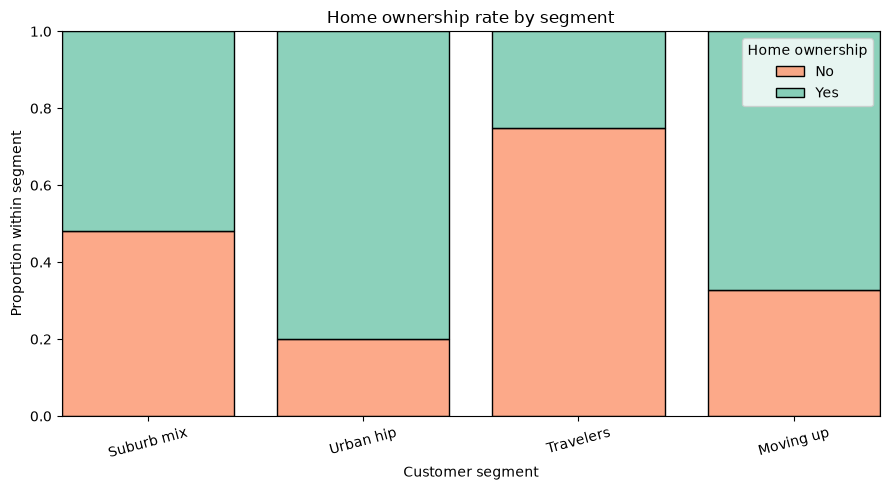

In [56]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x='Segment',
    hue='ownHome',
    multiple='fill',
    shrink=0.8,
    palette='Set2'
)
plt.xlabel('Customer segment')
plt.ylabel('Proportion within segment')
plt.title('Home ownership rate by segment')
plt.xticks(rotation=15)
plt.legend(title='Home ownership', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

**3 · Test.** Is home ownership related to segment? State H₀ and H₁, run the test, conclude.

- **H₀:** Home ownership and customer segment are independent.
- **H₁:** Home ownership and customer segment are associated.
- **Conclusion:** χ²(3) = 45.47, p = 7.34 × 10⁻¹⁰. Reject H₀; the data provide strong evidence of an association between segment and home ownership.

In [57]:
from scipy.stats import chi2_contingency

ownership_segment_result = chi2_contingency(ownership_table)

print('H0: Home ownership and customer segment are independent.')
print('H1: Home ownership and customer segment are associated.')
print(f"chi-square: {ownership_segment_result.statistic:.4f}")
print(f"p-value: {ownership_segment_result.pvalue:.6g}")
print(f"degrees of freedom: {ownership_segment_result.dof}")
print('Expected counts under H0:')
print(pd.DataFrame(
    ownership_segment_result.expected_freq,
    index=ownership_table.index,
    columns=ownership_table.columns
).round(2))

H0: Home ownership and customer segment are independent.
H1: Home ownership and customer segment are associated.
chi-square: 45.4723
p-value: 7.34326e-10
degrees of freedom: 3
Expected counts under H0:
ownHome     ownNo  ownYes
Segment                  
Moving up    37.1    32.9
Suburb mix   53.0    47.0
Travelers    42.4    37.6
Urban hip    26.5    23.5


**4 · Expected counts.** From your result in question 3, how many Travelers would you expect to own a
home **if H₀ were true**? Compare it with the observed count.

**Answer:** Under independence, the expected count is (80 Travelers × 141 owners) ÷ 300 = **37.6**. The observed count is **60**, which is 22.4 more than expected.

In [58]:
traveler_expected_owners = ownership_segment_result.expected_freq[
    ownership_table.index.get_loc('Travelers'),
    ownership_table.columns.get_loc('ownYes')
]
traveler_observed_owners = ownership_table.loc['Travelers', 'ownYes']

print(f'Expected Travelers who own a home under H0: {traveler_expected_owners:.2f}')
print(f'Observed Travelers who own a home: {traveler_observed_owners}')
print(f'Difference (observed - expected): {traveler_observed_owners - traveler_expected_owners:.2f}')

Expected Travelers who own a home under H0: 37.60
Observed Travelers who own a home: 60
Difference (observed - expected): 22.40


**5 · One category.** Is the split between owners and non-owners 50/50 in the population?
Use a chi-square test **and** a binomial test, and check they agree.

**Answer:** There are 141 owners (47.0%) and 159 non-owners. The chi-square test gives χ²(1) = 1.08, p = 0.299; the exact two-sided binomial test gives p = 0.326. Both p-values exceed 0.05, so both tests fail to reject a 50/50 population split. The p-values differ because the binomial test is exact while the chi-square test is an approximation.

In [59]:
from scipy.stats import binomtest, chisquare

ownership_counts = df['ownHome'].value_counts().reindex(['ownYes', 'ownNo'])
ownership_chisquare = chisquare(f_obs=ownership_counts)
owners = int(ownership_counts['ownYes'])
ownership_binomial = binomtest(
    k=owners,
    n=len(df),
    p=0.5,
    alternative='two-sided'
)

print('Observed owner/non-owner counts:')
print(ownership_counts)
print(f'Chi-square: {ownership_chisquare.statistic:.4f}, p-value: {ownership_chisquare.pvalue:.6g}')
print(f'Binomial test: observed owner proportion = {owners / len(df):.3f}, p-value: {ownership_binomial.pvalue:.6g}')
print('Both tests use alpha = 0.05 and lead to the same decision:',
      'reject H0' if ownership_chisquare.pvalue < 0.05 else 'fail to reject H0')

Observed owner/non-owner counts:
ownHome
ownYes    141
ownNo     159
Name: count, dtype: int64
Chi-square: 1.0800, p-value: 0.298698
Binomial test: observed owner proportion = 0.470, p-value: 0.326354
Both tests use alpha = 0.05 and lead to the same decision: fail to reject H0


**6 · Gender and ownership.** Test whether home ownership is related to gender.

Write the one-sentence conclusion for a report.

**Answer:** Home ownership was not significantly associated with gender, χ²(1) = 0.157, p = 0.692; the observed ownership rates were 48.4% for women and 45.5% for men.

In [60]:
gender_ownership_table = pd.crosstab(df['gender'], df['ownHome'])
gender_ownership_rates = pd.crosstab(
    df['gender'], df['ownHome'], normalize='index'
)
gender_ownership_result = chi2_contingency(gender_ownership_table)

print('Counts:')
print(gender_ownership_table)
print('\nOwnership rates by gender:')
print(gender_ownership_rates.round(3))
print(f"\nchi-square: {gender_ownership_result.statistic:.4f}")
print(f"p-value: {gender_ownership_result.pvalue:.6g}")
print(f"degrees of freedom: {gender_ownership_result.dof}")

Counts:
ownHome  ownNo  ownYes
gender                
Female      81      76
Male        78      65

Ownership rates by gender:
ownHome  ownNo  ownYes
gender                
Female   0.516   0.484
Male     0.545   0.455

chi-square: 0.1569
p-value: 0.692067
degrees of freedom: 1


**7 · No code.** In question 3 the test said ownership is related to segment. The **Travelers**
segment is the oldest (mean age 58) and has no children.

Give one reason the segment–ownership relationship might **not** be about segment at all. What week-4 word describes it?

**Answer:** Age or life stage could influence both segment membership and the likelihood of owning a home. That makes age a potential **confounding variable**, so the association with segment may partly reflect age differences rather than a segment effect itself.

**8 · Put it together.** The marketing team wants more subscribers. Someone says: *"Home owners have
more money. Let's send the subscription offer only to home owners."*

Do the four steps in order. Each step uses what the step before it told you.

**a · Predict, then describe.** Question 3 found that owning a home is related to segment. §3.3 found
that subscribing is related to segment. So do you expect owning a home to be related to subscribing?
Write your guess **first**. Then make the two-way table of `ownHome` against `subscribe`, and the same
as rates per row.

- **My guess:** I would expect some association because both home ownership and subscription vary by segment, although this is not guaranteed.
- **What the rates show:** The subscription rate is **13.8% for non-owners** (22/159) and **12.8% for owners** (18/141), a very small difference.

**b · Draw.** The filled bar chart above shows almost identical subscription proportions for owners and non-owners.

**c · Test.** Is subscribing related to home ownership? Report χ², p and the degrees of freedom.

- **H₀:** Subscription and home ownership are independent.
- **H₁:** Subscription and home ownership are associated.
- **Conclusion:** χ²(1) = 0.010, p = 0.919. Fail to reject H₀; this sample provides no evidence of an association.

**d · Decide.** Do not send the offer only to home owners: their subscription rate (12.8%) is slightly below the non-owner rate (13.8%), and the difference is not significant (p = 0.919). Use **Segment** to prioritize outreach instead: subscription rates are 20.0% in Moving up and Urban hip, 12.5% in Travelers, and 6.0% in Suburb mix; the segment–subscription association was significant (χ²(3) = 9.30, p = 0.025). Home ownership is also associated with segment (χ²(3) = 45.47, p < 0.001), but that does not make ownership a useful direct targeting rule. The original guess was **not supported** by the direct test of ownership against subscription.

Counts:
subscribe  subNo  subYes
ownHome                 
ownNo        137      22
ownYes       123      18

Subscribe rates by ownership status:
subscribe  subNo  subYes
ownHome                 
ownNo      0.862   0.138
ownYes     0.872   0.128


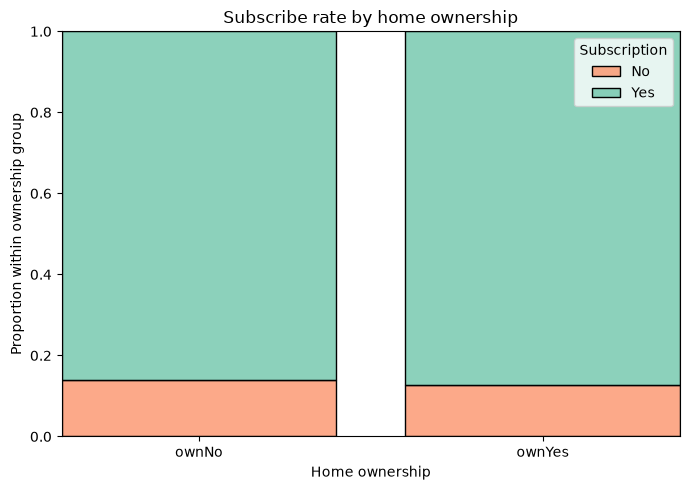

H0: Subscription and home ownership are independent.
H1: Subscription and home ownership are associated.
chi-square: 0.0104
p-value: 0.918686
degrees of freedom: 1


In [61]:
ownership_subscription_table = pd.crosstab(df['ownHome'], df['subscribe'])
ownership_subscription_rates = pd.crosstab(
    df['ownHome'], df['subscribe'], normalize='index'
)

print('Counts:')
print(ownership_subscription_table)
print('\nSubscribe rates by ownership status:')
print(ownership_subscription_rates.round(3))

plt.figure(figsize=(7, 5))
sns.histplot(
    data=df,
    x='ownHome',
    hue='subscribe',
    multiple='fill',
    shrink=0.8,
    palette='Set2'
)
plt.xlabel('Home ownership')
plt.ylabel('Proportion within ownership group')
plt.title('Subscribe rate by home ownership')
plt.legend(title='Subscription', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

ownership_subscription_result = chi2_contingency(ownership_subscription_table)
print('H0: Subscription and home ownership are independent.')
print('H1: Subscription and home ownership are associated.')
print(f"chi-square: {ownership_subscription_result.statistic:.4f}")
print(f"p-value: {ownership_subscription_result.pvalue:.6g}")
print(f"degrees of freedom: {ownership_subscription_result.dof}")

**9 · Check expected counts.** The test in §3.3 said subscribing is related to segment, p = 0.025. But it was run on 300 rows, and
the smallest cell in the table — Suburb mix subscribers — holds **6 people**.

A common conservative guideline is that every expected cell count should be at least 5 (some references allow limited exceptions, provided none is below 1). If expected counts are too small, use an exact or Monte Carlo test, or combine categories only when doing so makes substantive sense.

**Answer:** The minimum expected count is **6.67** (Urban hip subscribers), and all eight expected counts are at least 5. The usual expected-count condition is met, so the χ² p-value of 0.025 can be reported without a low-expected-count caveat. The observed count of 6 is not the expected count. Because the data are simulated, the finding should still be interpreted as a method exercise rather than a real business conclusion.

In [62]:
from scipy.stats import chi2_contingency

segment_subscription_result = chi2_contingency(table2)
expected_segment_subscription = pd.DataFrame(
    segment_subscription_result.expected_freq,
    index=table2.index,
    columns=table2.columns
)
minimum_expected = expected_segment_subscription.to_numpy().min()

print('Expected counts under H0:')
print(expected_segment_subscription.round(2))
print(f'\nMinimum expected count: {minimum_expected:.2f}')
print('All expected counts are at least 5:', bool((expected_segment_subscription >= 5).to_numpy().all()))
print(f'Chi-square p-value: {segment_subscription_result.pvalue:.6g}')
print('Conclusion: no expected cell is below 5, so the usual expected-count condition is met. '
      'Report the p-value with the note that the data are simulated.')

Expected counts under H0:
subscribe   subNo  subYes
Segment                  
Moving up   60.67    9.33
Suburb mix  86.67   13.33
Travelers   69.33   10.67
Urban hip   43.33    6.67

Minimum expected count: 6.67
All expected counts are at least 5: True
Chi-square p-value: 0.0253565
Conclusion: no expected cell is below 5, so the usual expected-count condition is met. Report the p-value with the note that the data are simulated.


---
# ✅ Done — hand it in

**Complete all nine questions before you submit. No cell is designed to fail.**

1. **Run All**, no red. 2. Save, **commit and sync**. 3. On Moodle: **this notebook**. 4. **Stop your Codespace**.

## What you can now do

- [ ] build a two-way table with `pd.crosstab`, and turn it into **rates per row** with `normalize='index'`
- [ ] draw one bar per group with `countplot`, grouped bars for counts and **filled bars for rates**, and say when each is right
- [ ] run a one-way chi-square on one category, and a two-way chi-square on a crosstab
- [ ] read `expected_freq`, and compute one expected count from the **marginal sums**
- [ ] write the χ² formula in words, and say where its p-value comes from
- [ ] explain why the same proportions with a tenth of the data stop being significant
- [ ] run a binomial test on a single rate against a claimed value
- [ ] say what a significant chi-square does **not** tell you — which groups, or why

## Coming up

**Your final survey is due at the end of this week.** **Next week:** a number across groups — the
two-sample t-test and ANOVA.